# What Reviews Reveal About Skin-Type Fit
### Mining Sephora moisturizer reviews to improve skincare quiz recommendations

**Neha Kollikara · INFO 4360 Final Project · Path B: Understanding/Extraction**

## Setup

In [1]:
# Reload src/ functions automatically when they change
%load_ext autoreload
%autoreload 2

# Imports
import os
import sys
sys.path.append("..")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_data, plot_bar

In [2]:
# Complaint categories, in the order used for labeling (notebook 4), with readable names for charts
CATEGORY_NAMES = {
    "greasy_heavy": "Greasy / heavy",
    "breakouts": "Breakouts",
    "not_moisturizing": "Not moisturizing",
    "irritation": "Irritation",
    "fragrance": "Fragrance",
    "pilling": "Pilling",
    "no_results": "No results",
    "price_value": "Price / value",
    "packaging": "Packaging",
    "reformulation": "Reformulation",
    "other": "Other",
}
CATEGORIES = list(CATEGORY_NAMES)

# Skin types ordered from dry to oily, with one consistent color each across all charts
SKIN_ORDER = ["dry", "normal", "combination", "oily"]
SKIN_COLORS = {"dry": "#C8325A", "normal": "#E89AAE", "combination": "#B7A6AB", "oily": "#1A1A1A"}

# Load Claude's labels and drop the 3 reviews that couldn't be labeled (notebook 4)
labeled = pd.read_csv("../Data/claude_labels.csv", dtype={"review_id": str},
                      parse_dates=["submission_time"])
labeled = labeled.dropna(subset=["any_complaint"]).copy()
labeled[CATEGORIES + ["any_complaint"]] = labeled[CATEGORIES + ["any_complaint"]].astype(int)
print(f"Labeled reviews: {len(labeled):,}")
print(labeled.groupby("skin_type").size())

Labeled reviews: 7,997
skin_type
combination    1999
dry            2000
normal         2000
oily           1998
dtype: int64


## 1. Problem Statement

## 2. Data and Descriptive Analysis

## 3. Text Analysis

## 4. Tool Integration: Labeling Complaints with Claude

## 5. Complaint Analysis: Which Complaints Concentrate in Which Skin Types?

**Approach:** Claude labeled each of the 7,997 sampled reviews with zero or more complaint categories (Section 4). For each category, the complaint rate is the share of reviews that mention it. Rates are used instead of counts because they are comparable across groups. The sample has an equal number of reviews per product and skin type, so skin types can be compared fairly.

The analysis starts broad, with complaint rates overall and by skin type across all 20 products combined, and then narrows to individual products, where the recommendations come from.

Reviews with at least one complaint: 35.9%


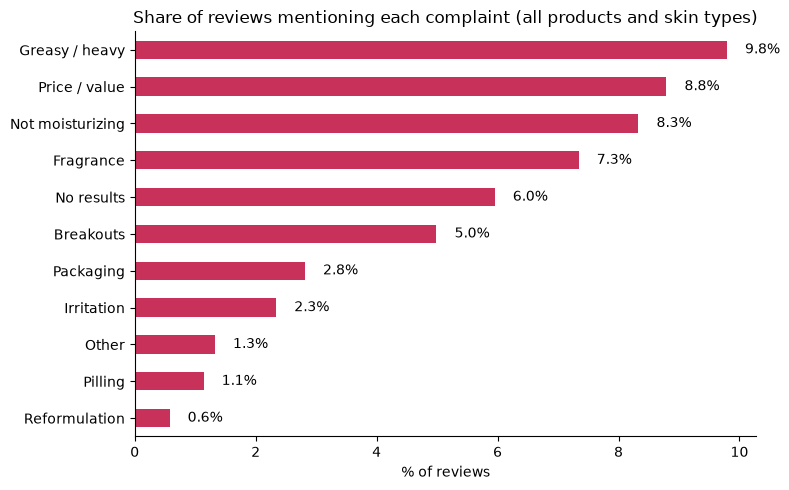

In [3]:
# Share of reviews mentioning each complaint, across the whole sample
overall = (labeled[CATEGORIES].mean() * 100).rename(CATEGORY_NAMES).sort_values()
print(f"Reviews with at least one complaint: {labeled['any_complaint'].mean():.1%}")

# Horizontal bar chart, largest complaint at the top
ax = overall.plot(kind="barh", color="#C8325A", figsize=(8, 5))
for i, v in enumerate(overall):
    ax.text(v + 0.3, i, f"{v:.1f}%", va="center", fontsize=10)
ax.set_title("Share of reviews mentioning each complaint (all products and skin types)")
ax.set_xlabel("% of reviews")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

skin_type,dry,normal,combination,oily
Greasy / heavy,6.6,9.8,10.6,12.1
Breakouts,4.0,5.1,5.6,5.4
Not moisturizing,11.6,8.2,8.4,5.1
Irritation,2.6,2.0,2.6,2.3
Fragrance,7.0,7.8,7.4,7.3
Pilling,1.1,1.2,1.2,1.1
No results,5.4,6.0,6.7,5.8
Price / value,9.4,8.5,9.0,8.4
Packaging,3.4,2.5,3.3,2.1
Reformulation,0.6,0.6,0.6,0.5


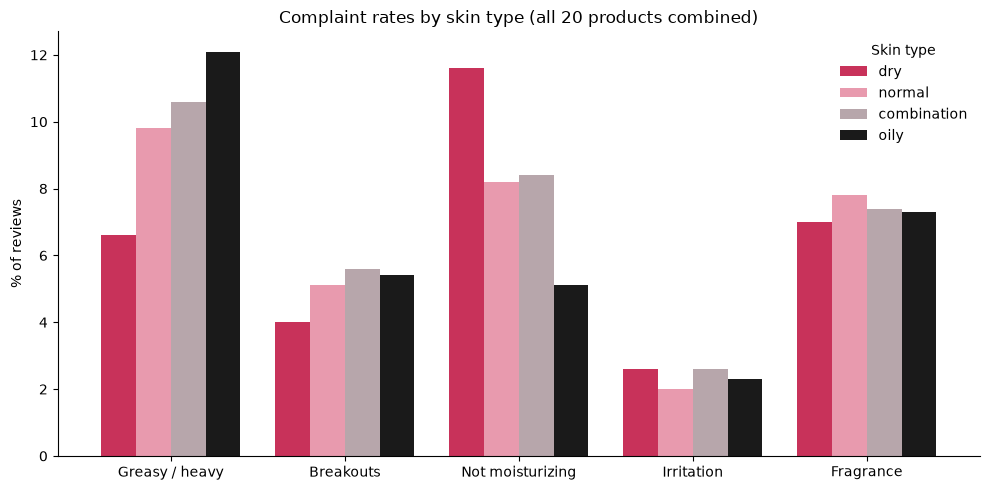

In [4]:
# Complaint rates by skin type, all 20 products combined
by_skin = (labeled.groupby("skin_type")[CATEGORIES + ["any_complaint"]].mean() * 100).T
by_skin = by_skin[SKIN_ORDER].rename(index=CATEGORY_NAMES | {"any_complaint": "Any complaint"}).round(1)
display(by_skin)

# Grouped bar chart for the complaints most related to skin-type fit
skin_fit = ["Greasy / heavy", "Breakouts", "Not moisturizing", "Irritation", "Fragrance"]
ax = by_skin.loc[skin_fit].plot(kind="bar", color=[SKIN_COLORS[s] for s in SKIN_ORDER],
                                figsize=(10, 5), rot=0, width=0.8)
ax.set_title("Complaint rates by skin type (all 20 products combined)")
ax.set_ylabel("% of reviews")
ax.legend(title="Skin type", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Observations**

About a third of reviews contain a complaint with 35.9% of reviews mentioning at least one complaint, even though most reviews in the sample are positive. Many complaints appear inside otherwise favorable reviews ("love it, but…"), which is why every review was labeled rather than only low-rated ones.

**Most common complaints:** greasy/heavy texture (9.8% of reviews), price/value (8.8%), not moisturizing enough (8.3%), and fragrance (7.3%), followed by no results (6.0%) and breakouts (5.0%). Packaging, irritation, pilling, reformulation, and other each appear in under 3% of reviews. At that rate, a product–skin type group of about 100 reviews would contain only one to three mentions, too few to compare reliably, so the product-level analysis below focuses on the six most common categories. Since Claude over-applied "no results" in the agreement test (Section 4), its 6.0% rate is an upper bound.

**Skin types complain about opposite things:** With 2,000 reviews per skin type, differences under about 2 percentage points are within normal sampling variation. The differences for texture and moisture are well beyond that:
- Greasy/heavy complaints rise steadily from dry to oily skin: 6.6% (dry), 9.8% (normal), 10.6% (combination), 12.1% (oily). Oily-skin reviewers mention greasiness almost twice as often as dry-skin reviewers.
- Not moisturizing complaints run in the opposite direction: 11.6% (dry), 8.2% (normal), 8.4% (combination), 5.1% (oily). Dry-skin reviewers mention it more than twice as often as oily-skin reviewers.
- Breakouts are slightly less common for dry skin (4.0%) than for the other types (5.1–5.6%), a smaller gap near the edge of sampling noise.

**Some complaints don't depend on skin type:** Fragrance (7.0–7.8%), price (8.4–9.4%), irritation (2.0–2.6%), and the overall share of reviews with any complaint (34.8–37.2%) are nearly identical across skin types. Shoppers of every skin type are about equally likely to be dissatisfied, but the reason differs by skin type, which is exactly the information the skincare quiz could use. Complaints that don't vary by skin type, like fragrance, are product-level issues better handled through filters (for example, fragrance-free) than through skin-type quiz rules.

**Why look at individual products next?** These rates combine all 20 products, so they show a general tendency rather than which specific products to adjust. The next step compares skin types within each product, where the quiz recommendations come from.

  ## 6. Key Findings

  ## 7. Business Implications and Recommendations

  ## 8. Ethical and Privacy Considerations